In [1]:
import RandomTilings as RT
import numpy as np
import matplotlib.pyplot as plt
from mpmath import mp
mp.pretty = 1

# Magnitude Analysis

In [2]:
## Using Periodic trick
def update_weight(W,E):
    M,N = W.shape
    M,N = M//2,N//2
    W1 = W.copy() + 1*(W==0)
    E1 = E.copy() + 1*(W==0)
    for m in range(M):
        for n in range(N):
            w,x,y,z     = W1[2*m,2*n],W1[2*m,2*n+1],W1[2*m+1,2*n],W1[2*m+1,2*n+1]
            ew,ex,ey,ez = E1[2*m,2*n],E1[2*m,2*n+1],E1[2*m+1,2*n],E1[2*m+1,2*n+1]

            Ixy = ex+ey
            Iwz = ew+ez
            if Ixy>Iwz:
                d           = w*z 
                w,x,y,z     = 1/w,y/d,x/d,1/z
                ew,ex,ey,ez = -ew,ey-Iwz,ex-Iwz,-ez
            elif Ixy<Iwz:
                d           = x*y
                w,x,y,z     = z/d,1/x,1/y,w/d
                ew,ex,ey,ez = ez-Ixy,-ex,-ey,ew-Ixy
            else:
                d           = w*z + x*y
                w,x,y,z     = z/d, y/d, x/d, w/d
                ew,ex,ey,ez = ez-Ixy,ey-Ixy,ex-Ixy,ew-Ixy

            W1[2*m,2*n],W1[2*m,2*n+1],W1[2*m+1,2*n],W1[2*m+1,2*n+1] = w,x,y,z
            E1[2*m,2*n],E1[2*m,2*n+1],E1[2*m+1,2*n],E1[2*m+1,2*n+1] = ew,ex,ey,ez

    I1 = np.concat([np.arange(1,2*N),[0]])
    I2 = np.concat([[-1],np.arange(2*M-1)])

    W1 = W1[:,I1]
    W1 = W1[I2]
    E1 = E1[:,I1]
    E1 = E1[I2]
    return W1,E1

In [24]:
n      = 10000
mp.dps = 100
r      = 4


def diff(theta,phi):
    return np.abs(np.sin((theta-phi)/2))

alpha = 0.
beta = np.pi/25
gamma = 4*np.pi/5
delta = 6*np.pi/5
epsilon = 8*np.pi/5


w = np.array([[1+1j,diff(epsilon,gamma),diff(gamma,beta),diff(delta,gamma),diff(gamma,beta),diff(beta,gamma)],
[diff(gamma,beta),diff(beta,epsilon),1+r*1j,diff(beta,delta),1+1j,1+r*1j],
[diff(delta,gamma),diff(epsilon,delta),diff(delta,beta),1+1j,diff(delta,alpha),diff(alpha,delta)],
[diff(gamma,alpha),diff(alpha,epsilon),diff(beta,alpha),diff(alpha,delta),1+r*1j,1+1j]])

mpc  = np.vectorize(mp.mpc)
real = np.vectorize(np.real)
imag = np.vectorize(np.imag)
w = mpc(w)
W = real(w)
E = imag(w)

WT = [W]
ET = [E]
for _ in range(n):
    W,E = update_weight(W,E)
    WT += [W]
    ET += [E]

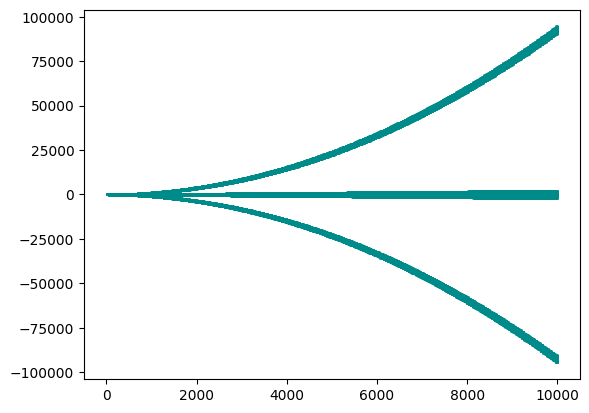

In [25]:
mplog10 = np.vectorize(mp.log10) 
tmp = mplog10(np.abs(WT))

plt.scatter([24*[k+1] for k in range(n)] ,[tmp[k].ravel()for k in range(n)],c = 'darkcyan',s = 1)

## Log version

In [26]:
def logaddexp(a,b,mpmath=False):
    if mpmath:
        return max(a,b)+ mp.log(1+mp.exp(-abs(a-b)))
    else:
        return max(a,b)+ np.log(1+np.exp(-abs(a-b)))

def update_weight_log(W,E,mpmath=False):
    M,N = W.shape
    M,N = M//2,N//2
    W1 = W.copy() #+ 1*(W==0)
    E1 = E.copy() #+ 1*(W==0)
    for m in range(M):
        for n in range(N):
            w,x,y,z     = W1[2*m,2*n],W1[2*m,2*n+1],W1[2*m+1,2*n],W1[2*m+1,2*n+1]
            ew,ex,ey,ez = E1[2*m,2*n],E1[2*m,2*n+1],E1[2*m+1,2*n],E1[2*m+1,2*n+1]

            Ixy = ex+ey
            Iwz = ew+ez
            if Ixy>Iwz:
                d           = w+z 
                w,x,y,z     = -w,y-d,x-d,-z
                ew,ex,ey,ez = -ew,ey-Iwz,ex-Iwz,-ez
            elif Ixy<Iwz:
                d           = x+y
                w,x,y,z     = z-d,-x,-y,w-d
                ew,ex,ey,ez = ez-Ixy,-ex,-ey,ew-Ixy
            else:
                d           = logaddexp(w+z,x+y,mpmath)
                w,x,y,z     = z-d, y-d, x-d, w-d
                ew,ex,ey,ez = ez-Ixy,ey-Ixy,ex-Ixy,ew-Ixy

            W1[2*m,2*n],W1[2*m,2*n+1],W1[2*m+1,2*n],W1[2*m+1,2*n+1] = w,x,y,z
            E1[2*m,2*n],E1[2*m,2*n+1],E1[2*m+1,2*n],E1[2*m+1,2*n+1] = ew,ex,ey,ez

    I1 = np.concat([np.arange(1,2*N),[0]])
    I2 = np.concat([[-1],np.arange(2*M-1)])

    W1 = W1[:,I1]
    W1 = W1[I2]
    E1 = E1[:,I1]
    E1 = E1[I2]
    return W1,E1

In [27]:
n      = 10000
mp.dps = 100
r      = 4
mpmath = 0


def diff(theta,phi):
    return np.abs(np.sin((theta-phi)/2))

alpha = 0.
beta = np.pi/25
gamma = 4*np.pi/5
delta = 6*np.pi/5
epsilon = 8*np.pi/5


w = np.array([[1+1j,diff(epsilon,gamma),diff(gamma,beta),diff(delta,gamma),diff(gamma,beta),diff(beta,gamma)],
[diff(gamma,beta),diff(beta,epsilon),1+r*1j,diff(beta,delta),1+1j,1+r*1j],
[diff(delta,gamma),diff(epsilon,delta),diff(delta,beta),1+1j,diff(delta,alpha),diff(alpha,delta)],
[diff(gamma,alpha),diff(alpha,epsilon),diff(beta,alpha),diff(alpha,delta),1+r*1j,1+1j]])

mpc  = np.vectorize(mp.mpc)
real = np.vectorize(np.real)
imag = np.vectorize(np.imag)
if mpmath:
    w = mpc(w)
    W = real(w)
    E = imag(w)
    W = np.vectorize(mp.log)(W)
else:
    W = real(w)
    E = imag(w)
    W = np.log(W)


WT1 = [W]
ET1 = [E]
for _ in range(n):
    W,E = update_weight_log(W,E,mpmath)
    WT1 += [W]
    ET1 += [E]

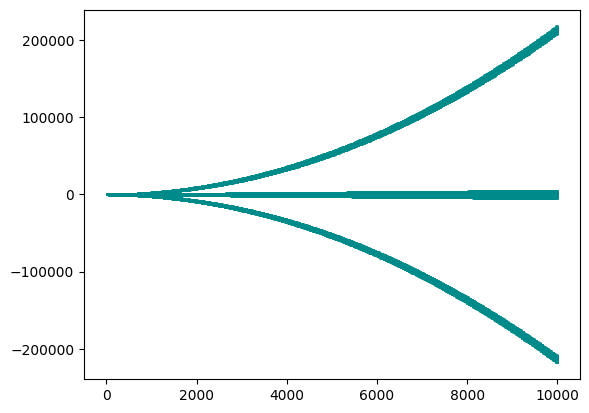

In [28]:
plt.scatter([24*[k+1]for k in range(n)],[WT1[k].ravel()for k in range(n)],c = 'darkcyan',s = 1)

## Compare

In [29]:
mplog = np.vectorize(mp.log)
logWT = mplog(WT)

In [45]:
WT1[3]

array([[ 0.3075786 ,  0.65316685,  0.        , -0.29540646, -0.40840077,
        -0.42666162],
       [-2.68584846, -2.77049129, -3.47281058, -0.43103004, -0.46192162,
        -3.82848945],
       [-2.59477654, -2.2666502 , -0.0527219 , -0.91224186, -0.43103004,
        -0.40840077],
       [ 0.80705128,  0.75686949,  0.75686949, -0.32732739, -0.25451633,
         3.11641991]])

In [47]:
logWT[3].astype(float)

array([[ 0.3075786 ,  0.65316685,  0.        , -0.29540646, -0.40840077,
        -0.42666162],
       [-2.68584846, -2.77049129, -3.47281058, -0.43103004, -0.46192162,
        -3.82848945],
       [-2.59477654, -2.2666502 , -0.0527219 , -0.91224186, -0.43103004,
        -0.40840077],
       [ 0.80705128,  0.75686949,  0.75686949, -0.32732739, -0.25451633,
         3.11641991]])

In [51]:
for k in range(len(WT)):
    tmp1 = logWT[k]
    tmp2 = WT1[k]
    I = tmp1 !=0
    tmp1 = tmp1[I]
    tmp2 = tmp2[I]
    print(k,'\t',float(np.max(abs(tmp1-tmp2)/abs(tmp1))))


0 	 1.072750864650815e-16
1 	 3.0117417671657218e-15
2 	 3.0117417671657218e-15
3 	 3.3541052405737678e-15
4 	 3.3541052405737678e-15
5 	 3.3541052405737678e-15
6 	 2.191743161167683e-15
7 	 3.1543905136598964e-15
8 	 9.578983870709923e-16
9 	 1.6557323393908504e-15
10 	 1.995432598298465e-15
11 	 1.995432598298465e-15
12 	 3.724480495554878e-15
13 	 2.258058856446503e-15
14 	 2.010353819150032e-15
15 	 3.4513733598203496e-15
16 	 3.6484923323155275e-15
17 	 3.6484923323155275e-15
18 	 5.2605688022213886e-15
19 	 5.114843144744166e-15
20 	 7.914024141839004e-15
21 	 7.45713034111882e-15
22 	 2.7491836261961095e-15
23 	 1.3345725939512444e-14
24 	 4.235766154626125e-14
25 	 1.3345725939512444e-14
26 	 7.519715013074502e-15
27 	 7.409994371233485e-15
28 	 1.220858867856822e-14
29 	 1.220858867856822e-14
30 	 1.0137937481150256e-14
31 	 1.0137937481150256e-14
32 	 2.053584311316355e-14
33 	 9.826165522832547e-15
34 	 1.424648385996651e-14
35 	 6.697721583269917e-15
36 	 7.217699436722452e

# Plotting version

In [ ]:
import numpy as np
import RandomTilings as RT
from RandomTilings._draw_dominos import draw_dominos
from RandomTilings._core import no_neighbor
from RandomTilingsTMP._draw_dominos import draw_dominos as draw_dominosTMP
from numba import jit,njit
from numba.typed import List 
from time import perf_counter
RT.config.set_hd_mode(1)
from mpmath import mp
mp.pretty = 1

weight_aztec = RT._weight_aztec.weight_aztec
def draw_Aztec(M,edge=0,paths=False,dots=False,orientation='diamond',coloring='standard',
                   show_gap=False,dpi=100):
        edge = str(edge)
        return draw_dominos(M,False,edge,paths,dots,orientation,coloring,show_gap,dpi)

def draw_AztecTMP(M,edge=0,paths=False,dots=False,rotated=True,coloring='standard',
                   show_gap=False,dpi=100,show_figure=False):
        edge = str(edge)
        return draw_dominosTMP(M,False,edge,paths,dots,rotated,coloring,show_gap,dpi,show_figure)



In [181]:
def logaddexp(a,b,mpmath=False):
    if mpmath:
        return max(a,b)+ mp.log(1+mp.exp(-abs(a-b)))
    else:
        return max(a,b)+ np.log(1+np.exp(-abs(a-b)))

def update_weight_log(W,E,mpmath=False):
    M,N = W.shape
    M,N = M//2,N//2
    W1 = W.copy() #+ 1*(W==0)
    E1 = E.copy() #+ 1*(W==0)
    for m in range(M):
        for n in range(N):
            w,x,y,z     = W1[2*m,2*n],W1[2*m,2*n+1],W1[2*m+1,2*n],W1[2*m+1,2*n+1]
            ew,ex,ey,ez = E1[2*m,2*n],E1[2*m,2*n+1],E1[2*m+1,2*n],E1[2*m+1,2*n+1]

            Ixy = ex+ey
            Iwz = ew+ez
            if Ixy>Iwz:
                d           = w+z 
                w,x,y,z     = -w,y-d,x-d,-z
                ew,ex,ey,ez = -ew,ey-Iwz,ex-Iwz,-ez
            elif Ixy<Iwz:
                d           = x+y
                w,x,y,z     = z-d,-x,-y,w-d
                ew,ex,ey,ez = ez-Ixy,-ex,-ey,ew-Ixy
            else:
                d           = logaddexp(w+z,x+y,mpmath)
                w,x,y,z     = z-d, y-d, x-d, w-d
                ew,ex,ey,ez = ez-Ixy,ey-Ixy,ex-Ixy,ew-Ixy

            W1[2*m,2*n],W1[2*m,2*n+1],W1[2*m+1,2*n],W1[2*m+1,2*n+1] = w,x,y,z
            E1[2*m,2*n],E1[2*m,2*n+1],E1[2*m+1,2*n],E1[2*m+1,2*n+1] = ew,ex,ey,ez

    I1 = np.concat([np.arange(1,2*N),[0]])
    I2 = np.concat([[-1],np.arange(2*M-1)])

    W1 = W1[:,I1]
    W1 = W1[I2]
    E1 = E1[:,I1]
    E1 = E1[I2]
    return W1,E1
    
def comp_prop_log(W,E,mpmath=False):
    M,N = W.shape
    M,N = M//2,N//2

    P   = np.zeros((M,N)).astype('O')
    for m in range(M):
        for n in range(N):
            w,x,y,z     = W[2*m,2*n],W[2*m,2*n+1],W[2*m+1,2*n],W[2*m+1,2*n+1]
            ew,ex,ey,ez = E[2*m,2*n],E[2*m,2*n+1],E[2*m+1,2*n],E[2*m+1,2*n+1]

            Ixy = ex+ey
            Iwz = ew+ez
            if Ixy>Iwz:
                P[m,n] = 0
                continue
            elif Ixy < Iwz:
                P[m,n] = -np.inf
                continue
            tmp = logaddexp(w+z,x+y,mpmath)
            if tmp == -np.inf :
                P[m,n] = np.log(1/2)
            else:
                P[m,n] = w+z-tmp
    return P



@njit("(int64, int64, int64, int64, int64)",inline = 'always')
def idx_correction(Size,WShape1,WShape2,m,n):
    m = WShape1 - (Size-m-1) % WShape1 - 1
    n = n % WShape2 
    return m,n

def comp_PTower_log(N,W,E,mpmath):
    L1,L2 = W.shape
    if L1%2==1:
        W = np.vstack([W,W])
        E = np.vstack([E,E])
    if L2%2==1:
        W = np.hstack([W,W])
        E = np.hstack([E,E])
    PT = [comp_prop_log(W,E,mpmath).astype(float)]
    for _ in range(N-1):
        W,E = update_weight_log(W,E,mpmath)
        PT += [comp_prop_log(W,E,mpmath).astype(float)]
    return List(PT[::-1])


@njit("(ListType(Array(float64, 2, 'C', False, aligned=True)),)")         
def shuffling(PT):
    N = 2*len(PT)
    M = np.zeros((N,N),dtype=np.int8)

    # Initiate
    A = N//2-1
    prob = PT[0][1,0]
    #print(PT[0])


    L1,L2 = PT[0].shape

    if np.log(np.random.random())<prob:
        M[A,A],M[A+1,A+1]= 1,1
        M[A,A+1],M[A+1,A]= 0,0
    else:
        M[A,A],M[A+1,A+1]= 0,0
        M[A,A+1],M[A+1,A]= 1,1

    
    for k in range(1,N//2):
        A = N//2-1-k   

        # destruction + flip (+ reconstruct)
        for m in range(k+1):
            for n in range(k+1):
                # destruction + flip
                tmp = M[A+2*m,A+2*n]+M[A+2*m+1,A+2*n]+M[A+2*m,A+2*n+1]+M[A+2*m+1,A+2*n+1]
                if tmp>1:
                    M[A+2*m,A+2*n],M[A+2*m+1,A+2*n],M[A+2*m,A+2*n+1],M[A+2*m+1,A+2*n+1]=0,0,0,0
                elif tmp == 1:
                    M[A+2*m,A+2*n],M[A+2*m+1,A+2*n+1]=M[A+2*m+1,A+2*n+1],M[A+2*m,A+2*n]
                    M[A+2*m,A+2*n+1],M[A+2*m+1,A+2*n]=M[A+2*m+1,A+2*n],M[A+2*m,A+2*n+1]

        for m in range(k+1):
            for n in range(k+1):
                if no_neighbor(M,k,m,n):
                    
                    # r = L1 - (k-m) % L2 - 1
                    # s = n % L2
                    r,s = idx_correction(k+1,L1,L2,m,n)
                    prob = PT[k][r,s]


                    if np.log(np.random.random())<prob:
                        M[A+2*m,A+2*n],M[A+2*m+1,A+2*n+1]= 1,1
                        M[A+2*m,A+2*n+1],M[A+2*m+1,A+2*n]= 0,0
                    else:
                        M[A+2*m,A+2*n],M[A+2*m+1,A+2*n+1]= 0,0
                        M[A+2*m,A+2*n+1],M[A+2*m+1,A+2*n]= 1,1
    return M

    

In [182]:
r = 4
def diff(theta,phi):
    return np.abs(np.sin((theta-phi)/2))

alpha = 0.
beta = np.pi/25
gamma = 4*np.pi/5
delta = 6*np.pi/5
epsilon = 8*np.pi/5


w = np.array([[1+1j,diff(epsilon,gamma),diff(gamma,beta),diff(delta,gamma),diff(gamma,beta),diff(beta,gamma)],
[diff(gamma,beta),diff(beta,epsilon),1+r*1j,diff(beta,delta),1+1j,1+r*1j],
[diff(delta,gamma),diff(epsilon,delta),diff(delta,beta),1+1j,diff(delta,alpha),diff(alpha,delta)],
[diff(gamma,alpha),diff(alpha,epsilon),diff(beta,alpha),diff(alpha,delta),1+r*1j,1+1j]])

Reduction	 0.05178940005134791
Shuffling 	 2.693828499992378
Plotting  	 3.853189800051041
-------------------------------------
Total     	 6.600219400017522


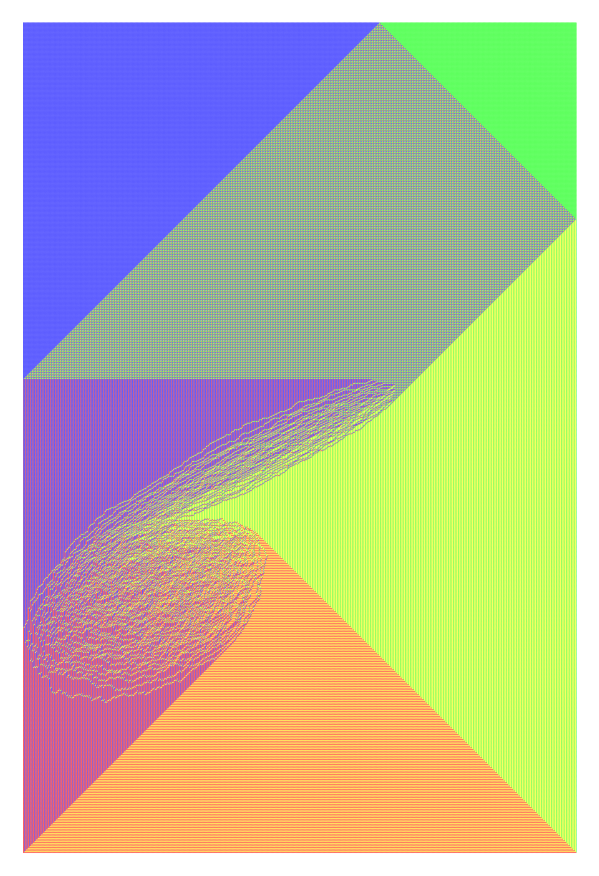

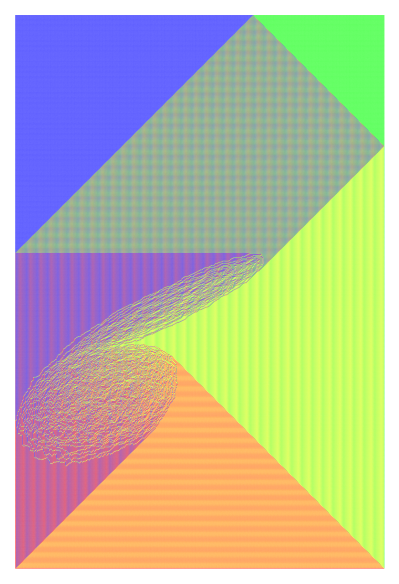

In [188]:
n = 1000
mp.dps = 16
mpmath = 0
if mpmath:
    mpc  = np.vectorize(mp.mpc)
    real = np.vectorize(np.real)
    imag = np.vectorize(np.imag)
    W  = np.vectorize(mp.log)(real(mpc(w)))
    E  = imag(mpc(w))
else:
    W = np.log(w.real)
    E = w.imag



t0 = perf_counter()
t1 = perf_counter()
PT = comp_PTower_log(n,W,E,mpmath)
print('Reduction\t',perf_counter()-t1)

t1 = perf_counter()
M = shuffling(PT).astype(np.int8)
print('Shuffling \t',perf_counter()-t1)

t1 = perf_counter()
fig = draw_Aztec(M,coloring=[(255,33,33),(31,31,255),(32,255,32),(255,255,32)],
                 orientation='square',dpi =150)
ax = fig.axes[0]
ax.set_aspect(3/2,adjustable='box')
ax.invert_yaxis()
ax.invert_xaxis()
print('Plotting  \t',perf_counter()-t1)
print('-------------------------------------')
print('Total     \t', perf_counter()-t0)